# Практическая работа 9

Напишите программы с использованием Python или C# для решения
следующих задач:
1. Три игрока (с номерами 1, 2 и 3), имеющие изначально X, Y и Z
жетонов соответственно, играют в следующую игру. В каждом раунде каждый
игрок ставит на кон один жетон. Затем бросают кубик, на котором цифры 4, 5,
6 заменены на 1, 2 и 3. При выпадении числа i игрок с номером i забирает с
кона все три жетона. Игра заканчивается, когда кто-нибудь из игроков
проигрывает все жетоны. Введем функцию f(X, Y, Z), как среднюю
длительность игры (среднее количество раундов) при заданных начальных
капиталах X, Y, Z. Например, f(2, 2, 2) = 2. Ваша задача состоит в том, чтобы
определить эту функцию.
Для этого необходимо написать программу, моделирующую игру,
накопить экспериментальные результаты, проанализировать их, а затем
выдвигать гипотезы о виде функции f, проверять их для разных входных
значений, и, отбросив неподходящие, найти решение.

In [1]:
import random

def play_game(X, Y, Z):
    rounds = 0
    while X > 0 and Y > 0 and Z > 0:
        rounds += 1
        for i in range(1, 4):
            token = random.randint(1, 3)
            if token == i:
                if i == 1:
                    X += 3
                elif i == 2:
                    Y += 3
                else:
                    Z += 3
            else:
                if i == 1:
                    X -= 1
                elif i == 2:
                    Y -= 1
                else:
                    Z -= 1
    return rounds

def f(X, Y, Z, num_trials):
    total_rounds = 0
    for _ in range(num_trials):
        total_rounds += play_game(X, Y, Z)
    return total_rounds / num_trials

# Пример использования
X = 2
Y = 2
Z = 2
num_trials = 10
average_rounds = f(X, Y, Z, num_trials)
print(f"Среднее количество раундов для начальных капиталов {X}, {Y}, {Z}: {average_rounds}")

Среднее количество раундов для начальных капиталов 2, 2, 2: 2.4


2. Игрок A выбирает комбинацию из цифр 0 и 1 длиной 3 знака
(например, 001). Игрок B выбирает свою комбинацию (отличную от игрока A).
Подбрасывается монета и записываются результаты бросания (например,
101101..., где 0 обозначает «орел», а 1 — «решка»). Игра прекращается в тот
момент, когда в последовательности цифр на конце возникает комбинация,
выбранная A или B (побеждает A или B соответственно). Игра повторяется.
а) Оценить шансы на выигрыш каждого из игроков R(A,B) (т.е.
отношение числа выигрышей игрока B к числу выигрышей игрока A).
б) Для выбранной игроком A комбинации определить такую
комбинацию для игрока B, которая ему дает больше шансов на выигрыш.
Ниже представлена таблица значений R(A,B) для всевозможных
выбранных игроками A и B исходных комбинаций при «неограниченном
продолжении» игры (выделены наиболее выигрышные ситуации для игрока
B).

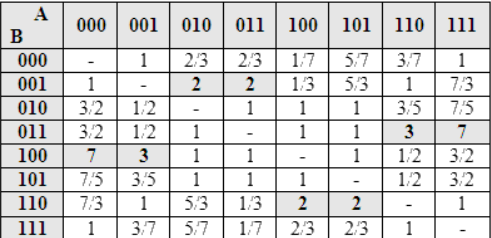

Пари является беспроигрышным (!) для игрока B. Парадокс заключается
в том, что какую бы комбинацию цифр не выбрал игрок A, его соперник B
может выбрать другую комбинацию, которая ему дает больше шансов на
выигрыш.

In [5]:
import random
def calculate_R(A, B):
    # Подсчет числа выигрышей игрока A и B
    wins_A = 0
    wins_B = 0

    for i in range(10000):  # Произвольное количество повторений игры
        sequence = ""  # Последовательность результатов бросаний монеты

        while True:
            # Бросаем монету и записываем результат
            result = random.choice([0, 1])
            sequence += str(result)

            # Проверяем, если в конце последовательности есть комбинация A или B
            if sequence.endswith(A):
                wins_A += 1
                break
            elif sequence.endswith(B):
                wins_B += 1
                break

    # Оценка шансов на выигрыш каждого из игроков
    R_A_B = wins_B / wins_A

    return R_A_B

# Пример использования функции
A = "001"
B = "110"

R_A_B = calculate_R(A, B)
print(f"Отношение числа выигрышей игрока B к числу выигрышей игрока A: {R_A_B}")

Отношение числа выигрышей игрока B к числу выигрышей игрока A: 1.0173492031470648


# Практическая работа 10

Напишите программы с использованием Python или C# для решения
следующих задач:
1. Пусть дана ось с отмеченными на ней целочисленными точками.
Предположим, что Чиполлино спрятался в точке 0, в точке N находится
пропасть, и сыщик Моркоу находится в точке k (0 < k < N). Сыщик ищет
Чиполлино случайным образом, блуждая по соседним целочисленным точкам.
Если он попадет в точку 0, то найдет Чиполлино, а если попадет в точку N, то
свалится в пропасть. С какой вероятностью сыщик найдет Чиполлино?
Под вероятностью какого-либо события (P) мы будем понимать
предельное значение частоты события, а именно, отношения числа успешных
(приведших к появлению данного события) испытаний (Nу) к общему числу
проведенных испытаний (N), то есть 𝑃 ~
𝑁у
𝑁
. Чем больше мы проведем
испытаний, тем точнее (в идеале) мы определяем численное значение
вероятности. Очевидно, что вероятность P удовлетворяет условию: 0 ≤ 𝑃 ≤ 1
Указание. Смоделируйте многократный поиск сыщика из точки k, доля
удачных попыток от общего их числа дает приближенную оценку искомой
вероятности. На основании этой оценки сформулируйте простую формулу для
нахождения вероятности события (обозначим ее 𝑃0(𝑘)), указанного в задаче.
Данную задачу можно решить точно, используя рекуррентную формулу:
𝑃0
(𝑘) =
𝑃0
(𝑘−1)
2
+
𝑃0
(𝑘+1)
2
при очевидных условиях, что 𝑃0(0) = 1 и
P0(N)=0, однако использовать рекурсию в такой форме неприемлемо, так как
глубина рекурсии неограниченна, что ведет к переполнению стека и краху
программы.
Упражнение 1.
Выведите рекуррентную зависимость 𝑃0(𝑘 + 1) от 𝑃0(𝑘), начиная с 𝑘 =
0 и, используя известное значение 𝑃0(𝑁), обратным ходом получите общее
выражение для 𝑃0(𝑘).

In [11]:
import random

def find_chipollino(N, k, num_trials):
    success_count = 0

    for _ in range(num_trials):
        position = k

        while position != 0 and position != N:
            position += random.choice([-1, 1])

        if position == 0:
            success_count += 1

    probability = success_count / num_trials
    return probability

N = 10  # Количество точек на оси
k = 5   # Позиция сыщика Моркоу
num_trials = 100  # Количество испытаний

probability = find_chipollino(N, k, num_trials)
print(f"Вероятность нахождения Чиполлино: {probability}")

Вероятность нахождения Чиполлино: 0.5


2. Пусть имеется “однорукий бандит” – игровой автомат с ручкой,
которой его запускают для игры. Считаем (для упрощения), что игра будет
типа “в орлянку”, и игрок имеет начальный капитал в одну монету. Игра
ведется до тех пор, пока игрок не обанкротится или выиграет N монет.
Промоделировать игру для N=10, определить вероятность (шансы) игрока
“сорвать указанный куш” и объяснить, почему автомат назвали “бандитом”.
Задача о разорении игрока аналогична задачи блуждания по отрезку [0,
N] с той лишь разницей, что требуется определить вероятность 𝑃𝑁(𝑘) достичь
точки N, находясь в точке k=1. Образно говоря, эти модели “связаны одной
цепью”. Последовательность испытаний, в которой каждое следующее
испытание зависит только от исхода предыдущего, называется цепью
Маркова. Многие реальные явления (например, броуновское движение
частиц, обслуживание телефонных линий) описываются данными
вероятностными моделями /2/.
Метод Монте-Карло универсален и применим как для задач, в условиях
которых присутствует элемент неопределенности, так и для полностью
детерминированных задач.
Иногда трудно найти алгоритм или функциональные зависимости для
решения сложных задач, однако возможно переформулировать условие задачи
таким образом, чтобы использовать для нахождения решения метод МонтеКарло. При этом задача упрощается, но за это приходится “расплачиваться”
временем решения и точностью результата.

In [7]:
import random

def simulate_game(N):
    wins = 0
    total_trials = 100000

    for _ in range(total_trials):
        coins = 1

        while coins > 0 and coins < N:
            if random.random() < 0.5:
                coins += 1
            else:
                coins -= 1

        if coins == N:
            wins += 1

    probability = wins / total_trials
    return probability

N = 10
probability = simulate_game(N)
print(f"Вероятность выигрыша {N} монет: {probability}")

Вероятность выигрыша 10 монет: 0.10085


# Практическая работа 11

Напишите программы с использованием Python или C# для решения
следующих задач:
1. Как известно, линейный конгруэнтный генератор псевдослучайных
чисел устроен следующим
образом. Зафиксированы числа a, c и m. Кроме того, у генератора есть
состояние s. Когда нужно
сгенерировать очередное псевдослучайное число, происходит присваивание
𝑠𝑛𝑒𝑤 ← (𝑠𝑜𝑙𝑑 · 𝑎 + 𝑐) 𝑚𝑜𝑑 𝑚,
после чего новое значение s объявляется ответом.
В этой задаче 𝑚 = 2
32, а числа a, c и начальное состояние s заданы во
входных данных.
Выведите следующие 10 чисел, которые сгенерирует этот генератор.
Формат входных данных
В первой строке записаны через пробел три целых числа: a, c и s.
Гарантируется, что эти числа
помещаются в 32-битный беззнаковый тип данных.
Формат выходных данных
Выведите 10 следующих чисел, которые сгенерирует получившийся
генератор.

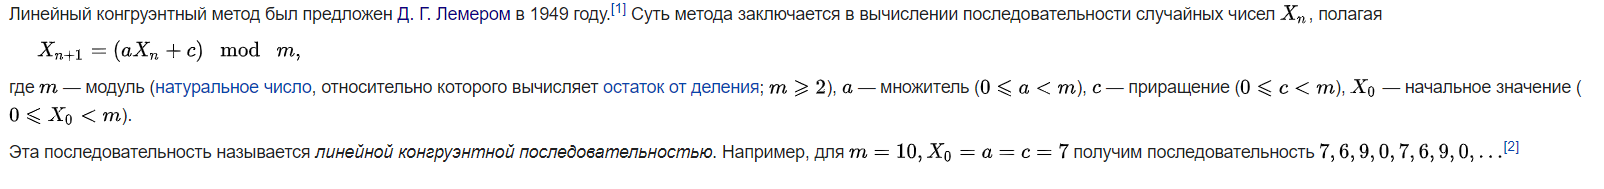

In [2]:
def linear_congruential_generator(a, c, s, m, n):
    result = []
    for _ in range(n):
        s = (s * a + c) % m
        result.append(s)
    return result

# Ввод параметров генератора 
a, c, s = map(int, input().split())

# Генерация следующих 10 чисел
generated_numbers = linear_congruential_generator(a, c, s, 2**32, 10)

# Вывод результатов
for number in generated_numbers:
    print(number)

 12 45 87


1089
13113
157401
1888857
22666329
271995993
3263951961
512717913
1857647705
816936025


# Практическая работа 12

Напишите программы с использованием Python или C# для решения
следующих задач:
1. Линейный конгруэнтный метод генерации псевдослучайных чисел
заключается в следующем. Выбирается произвольное число 𝑥0, а каждое
следующее вычисляется по формуле
𝑥𝑘 = (𝑎 ∗ 𝑥𝑘 − 1 + 𝑏) 𝑚𝑜𝑑 𝑚,
где коэффициенты выбраны особым образом. Например, a = 1664525, b
= 1013904223, m = 232.
Определить рекурсивную функцию, выводящую на экран n
псевдослучайных чисел для заданного 𝑥0.

In [8]:
def linear_congruential_generator(x0, n):
    a = 1664525
    b = 1013904223
    m = 2**32

    if n == 0:
        return
    else:
        x = (a * x0 + b) % m
        print(x)
        linear_congruential_generator(x, n-1)

# Пример вызова функции
x0 = 42  # Заданное начальное значение
n = 10  # Количество псевдослучайных чисел, которые нужно сгенерировать
linear_congruential_generator(x0, n)

1083814273
378494188
2479403867
955863294
1613448261
110225632
1921058495
508781842
3753001289
4271921684


# Практическая работа 13

Дан конечный автомат:
A = { a, b, c } (три возможных входных символа);
Σ = { 0, 1, 2, 3, 4 } (пять возможных состояний автомата);
𝑠0 = 0;
F = { 4 } (одно принимающее состояние);
ρ = { (a, 0) → 1, (b, 1) → 2, (b, 2) → 4, (c, 2) → 3, (b, 4) → 1, (любой
символ, 3) → 0 }.
Диаграмма конечного автомата представлена ниже

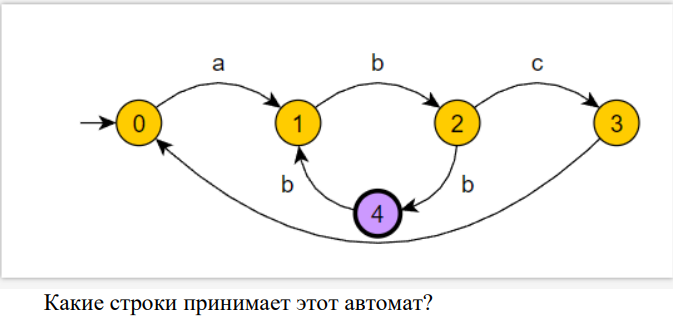

Смотрим: последовательность состояний 0-1-2-3-0-… соответствует
пропуску любого количества повторений abcs, где s — любой символ. Если же
после этого встретится abb, то такая строка будет принята.
То же самое можно сказать об abbbb (последовательность 0-1-2-4-1-2-4).
Вообще, благодаря циклу 1-2-4 автомат принимает “хвост” вида abb(bbb)*.
Звёздочкой обозначено произвольное число повторений последовательности в
скобках, т.е. a и (3i–1) подряд идущих b (для любого натурального i).
Благодаря этому же циклу автомат может пропускать строчки,
составленные не только из abcs, но из ab(bbb)*cs, т.е. с группами по (3i–2)
подряд идущих b.
Напишите программу, имитирующую работу данного конечного
автомата.

In [3]:
def simulate(input_string):
    current_state = 0
    for symbol in input_string:
        if current_state == 0:
            if symbol == 'a':
                current_state = 1
        elif current_state == 1:
            if symbol == 'b':
                current_state = 2
        elif current_state == 2:
            if symbol == 'b':
                current_state = 4
            elif symbol == 'c':
                current_state = 3
        elif current_state == 3:
            if symbol == 'b':
                current_state = 0
        elif current_state == 4:
            if symbol == 'b':
                current_state = 1
    return current_state == 4

# Пример использования

strings = ['abcs', 'abb', 'abbbb']

for string in strings:
    if simulate(string):
        print(f'Автомат принимает строку: {string}')
    else:
        print(f'Автомат не принимает строку: {string}')

Автомат не принимает строку: abcs
Автомат принимает строку: abb
Автомат не принимает строку: abbbb


# Практическая работа 14

1. Построить конечный автомат, распознающий последовательности из
нулей и единиц, содержащие чётное число единиц и не содержащие единиц,
идущих подряд друг за другом.
Примеры
00000 — принять
01000 — не принимать (нечётное число единиц)
00011 — не принимать (две единицы подряд)
10100 — принять
10110 — не принимать (нечётное число единиц и две единицы подряд)

In [3]:
def recognize_sequence(sequence):
    state = 'S0'
    for symbol in sequence:
        if state == 'S0':
            if symbol == '0':
                state = 'S0'
            elif symbol == '1':
                state = 'S1'
        elif state == 'S1':
            if symbol == '0':
                state = 'S2'
            elif symbol == '1':
                state = 'S1'
        elif state == 'S2':
            return False
    return state == 'S1'

# Примеры использования
print(recognize_sequence('00000'))  # принять
print(recognize_sequence('01000'))  # не принимать (нечётное число единиц)
print(recognize_sequence('00011'))  # не принимать (две единицы подряд)
print(recognize_sequence('10100'))  # принять
print(recognize_sequence('10110'))  # не принимать (нечётное число единиц и две единицы подряд)

False
False
True
False
False


# Практическая работ 15

1. Построить фрактал вида треугольник Серпинского.
Треугольник Серпинского строится следующим образом:
1)строится большой внешний треугольник (А);
2)строится треугольник, получающийся при соединении середин сторон
большого треугольника (Б);
3)строятся треугольники, получающиеся аналогично элементу Б, но в
качестве большого треугольника берутся треугольники, образованные
элементами А и Б.
Пример вывода:

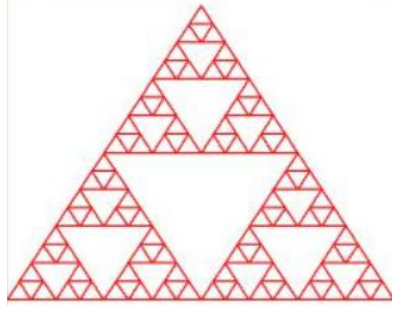

In [1]:
import turtle

def draw_triangle(length, depth):
    if depth == 0:
        for _ in range(3):
            turtle.forward(length)
            turtle.left(120)
    else:
        draw_triangle(length / 2, depth - 1)
        turtle.forward(length / 2)
        draw_triangle(length / 2, depth - 1)
        turtle.backward(length / 2)
        turtle.left(60)
        turtle.forward(length / 2)
        turtle.right(60)
        draw_triangle(length / 2, depth - 1)
        turtle.left(60)
        turtle.backward(length / 2)
        turtle.right(60)

# Настройка окна для отображения
turtle.setup(width=800, height=800)
turtle.speed(0)  # Наивысшая скорость

# Начальные координаты
turtle.penup()
turtle.goto(-300, -300)
turtle.pendown()

# Вызов функции для рисования треугольника Серпинского
draw_triangle(600, 4)

# Завершение работы
turtle.done()

# Практическая работа 16

Построение множества Мандельброта.
Алгоритм построения множества Мандельброта основан на
итеративном выражении:
Z[k + 1] = Z[k]* Z[k] + C (1),
где Z[k] и C – комплексные переменные, k – номер итерации, k = 1, 2, .;
Z[0] = 0.
Любое комплексное число Z можно представить в виде:
Z = x + y *i ,
где x и y это действительные числа, i – мнимая единица.
Для построения фрактала рассматривается прямоугольная область
комплексной плоскости. Для каждой точки C этой области выполняется N
итераций, т.е. находят N членов последовательности {zk } по формуле (1), при
этом k = 1, 2, , N ; z0 = 0 ; число N – задается пользователем.
Доказано, что множество Мандельброта размещается в круге радиуса 2
с центром в начале координат. Поэтому если для какой-либо точки C на
некоторой итерации k получается число комплексное число zk, модуль
которого r превышает число 2, то можно сделать вывод, что точка C не
принадлежит множеству Мандельброта. В этом случае итерационный процесс
можно завершить досрочно, не достигая заданного числа N . Если будут
проделаны все N итераций, и при этом окажется, что все получаемые числа zk
принадлежат кругу радиуса 2, то это не гарантирует, что точка C принадлежит
множеству Мандельброта. Однако при проведении компьютерного
эксперимента такие точки C считаются принадлежащими множеству
Мандельброта. Уменьшая шаг, с которым перебираются точки комплексной
плоскости, и, увеличивая число итераций, мы можем получать только более
подробные, но всегда лишь приближенные изображения множества
Мандельброта.
Постройте данный фрактал.

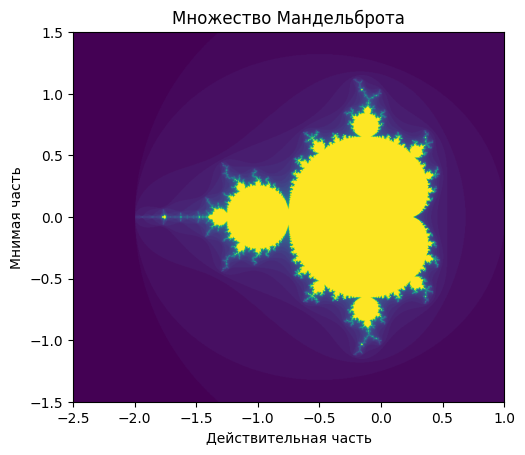

In [18]:
import numpy as np
import matplotlib.pyplot as plt

def mandelbrot(c, max_iter):
    z = 0
    for i in range(max_iter):
        z = z*z + c
        if abs(z) > 2:
            return i
    return max_iter

def create_mandelbrot(width, height, x_min, x_max, y_min, y_max, max_iter):
    image = np.zeros((width, height))
    for x in range(width):
        for y in range(height):
            real = x * (x_max - x_min) / (width - 1) + x_min
            imag = y * (y_max - y_min) / (height - 1) + y_min
            c = complex(real, imag)
            image[y, x] = mandelbrot(c, max_iter)
    return image

width = 800
height = 800
x_min = -2.5
x_max = 1
y_min = -1.5
y_max = 1.5
max_iter = 50

image = create_mandelbrot(width, height, x_min, x_max, y_min, y_max, max_iter)

plt.imshow(image, extent=(x_min, x_max, y_min, y_max))
plt.title("Множество Мандельброта")
plt.xlabel("Действительная часть")
plt.ylabel("Мнимая часть")
plt.show()